# De razones a metros: reconstruir el patrón absoluto de un tiro y contrastarlo con el artículo

**Pregunta:** ¿Se pueden convertir las razones publicadas en metros, y cómo sabemos que la conversión es correcta?

**Nivel 2: El método en la práctica** · Requiere: 01-the-data/01-the-corpus-and-the-cases · Tiempo de lectura: unos 25 minutos

## Objetivos

La ecuación clásica del tamaño medio necesita un volumen de roca en metros cúbicos y una masa de explosivo en kilogramos, pero el corpus publicado entrega solo razones adimensionales. Este notebook pregunta si las razones se pueden convertir en metros y, como una conversión errónea corrompería toda predicción clásica sin avisar, cómo sabemos que la conversión es correcta.

Al terminar, usted habrá:

- reconstruido el patrón de un tiro a partir de un diámetro de perforación registrado y las razones impresas, con el motor y con aritmética simple;
- reconstruido los 91 tiros de los nueve sitios cuya escala se conoce y visto las longitudes y los volúmenes de roca que implican;
- ejecutado la verificación del motor contra las 15 longitudes que declara el texto de la fuente, y leído dónde cae cada reconstrucción dentro de su rango declarado;
- medido el poder de esa verificación reemplazando el diámetro de Soma por otros valores, y visto qué haría un diámetro supuesto en Miami, el sitio que no publica ninguno.

## Preparación

Instale los paquetes con las versiones exactas de `notebooks/requirements.txt`. El motor es `blastfrag`, publicado en PyPI; los otros paquetes son su base numérica y la biblioteca de gráficos.

```bash
pip install blastfrag==0.4.0 numpy==2.5.4 matplotlib==3.11.2
```

La celda de preparación siguiente importa los paquetes, imprime sus versiones instaladas para que la salida registre qué motor produjo cada número, fija el estilo de los gráficos y define `show_table`, un ayudante de cuatro líneas que dibuja filas como tabla Markdown porque el entorno de notebooks no tiene `pandas`.

In [1]:
# Importaciones, versiones fijadas, estilo de gráficos y un ayudante que dibuja una tabla
import dataclasses
from importlib.metadata import version
from unittest.mock import patch

import blastfrag as bf
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import display

for name in ("blastfrag", "numpy", "matplotlib"):
    print(f"{name}=={version(name)}")

plt.rcParams.update({"axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False})


def show_table(header, rows, left=1):
    # Dibujar las filas como tabla Markdown, las primeras `left` columnas a la izquierda y las demás a la derecha
    lines = ["| " + " | ".join(header) + " |", "|" + ":---|" * left + "---:|" * (len(header) - left)]
    lines += ["| " + " | ".join(str(cell) for cell in row) + " |" for row in rows]
    text = "\n".join(lines)
    display({"text/markdown": text, "text/plain": text}, raw=True)

blastfrag==0.4.0
numpy==2.5.4
matplotlib==3.11.2


## Datos

Una fuente, leída desde el motor:

| Fuente | Titular y URL | Clase de licencia | Archivo que lee el notebook |
|---|---|---|---|
| El corpus y las narrativas de sitio (diámetros de perforación, alturas de banco, bordos, espaciamientos) | Hudaverdi, Kulatilake y Kuzu 2010, https://doi.org/10.1002/nag.957 | hechos numéricos reutilizados con cita; el artículo nunca se distribuye | la tabla y el registro `SITE_GEOMETRY` dentro del paquete `blastfrag` |

Cada entrada del registro guarda el diámetro de perforación de un sitio, cómo se obtuvo (citado del artículo, derivado de una longitud declarada, o no publicado) y las declaraciones dimensionales que el artículo hace sobre ese sitio, como rangos en metros.

## Método

Las razones de un tiro se definen respecto de su bordo `B` y de su diámetro de perforación `D`, así que una longitud conocida, el diámetro, fija todas las demás:

- bordo `B = (B/D) * D`
- espaciamiento `S = (S/B) * B`
- altura de banco `H = (H/B) * B`
- taco `T = (T/B) * B`

El volumen de roca por perforación es `V = B * S * H` y la masa de explosivo es `Q = Pf * V`, con `Pf` el factor de carga que el corpus imprime directamente (Hudaverdi, Kulatilake y Kuzu 2010, https://doi.org/10.1002/nag.957). El diámetro de perforación es la única cantidad que la tabla no puede dar, así que el motor guarda un registro con, para cada sitio, el diámetro que declara el texto del artículo, cómo se obtuvo y las longitudes en metros que el texto declara sobre el sitio. El registro es el único lugar donde entra el criterio, y el resto del notebook pregunta hasta dónde se puede confiar en él.

### Paso 1: el registro

La celda imprime, para cada sitio, el diámetro registrado, si fue citado del artículo, derivado de una longitud declarada o no publicado, cuántas longitudes en metros declara el artículo para el sitio (las declaraciones contra las que se probará la reconstrucción) y cuántos de sus tiros tienen escala. Busque los sitios que no son simplemente citados.

In [2]:
# El registro que trae el motor: el diámetro de cada sitio, de dónde salió y qué declara el artículo sobre él
train = bf.load_training_corpus()
sites = sorted({b.site for b in train})
rows = []
for site in sites:
    geometry = bf.SITE_GEOMETRY[site]
    members = [b for b in train if b.site == site]
    diameter = "-" if geometry.hole_diameter_mm is None else f"{geometry.hole_diameter_mm:g}"
    kind = "citado"
    if geometry.diameter_source.startswith("DERIVED"):
        kind = "derivado"
    elif geometry.diameter_source.startswith("NOT PUBLISHED"):
        kind = "no publicado"
    scaled = sum(bf.has_absolute_geometry(b) for b in members)
    rows.append((site, diameter, kind, len(geometry.narrative), f"{scaled} of {len(members)}"))
header = ["sitio", "D (mm)", "fuente de D", "longitudes declaradas",
          "tiros con escala"]
show_table(header, rows, left=3)
print("fuente del diámetro derivado:", bf.SITE_GEOMETRY["Reocin-UG"].diameter_source[:150], "...")

| sitio | D (mm) | fuente de D | longitudes declaradas | tiros con escala |
|:---|:---|:---|---:|---:|
| Akdaglar | 89 | citado | 1 | 22 of 22 |
| Dongri-Buzurg | 100 | citado | 3 | 9 of 9 |
| Enusa | 165 | citado | 1 | 12 of 12 |
| Miami | - | no publicado | 0 | 0 of 6 |
| Mrica | 76 | citado | 1 | 11 of 11 |
| Murgul | 165 | citado | 3 | 7 of 7 |
| Ozmert | 89 | citado | 2 | 7 of 7 |
| Reocin | 229 | citado | 1 | 10 of 10 |
| Reocin-UG | 91.2 | derivado | 1 | 6 of 6 |
| Soma | 210 | citado | 2 | 7 of 7 |

fuente del diámetro derivado: DERIVED, not published. The paper states an 18 m bench for the Reocin underground mine and gives no diameter. Inverting B = H / (H/B) and then D = B / ...


Ocho de los diez diámetros se citan del texto del artículo. Reocin-UG, con 91.2 mm, se deriva de una altura de banco declarada, y la línea de fuente impresa lo dice; Miami no tiene diámetro. El artículo declara 15 longitudes en metros en los otros nueve sitios, y Miami no tiene ninguna, así que nada puede ponerla a prueba. La tabla dice de dónde salió cada diámetro, no que sea correcto: los pasos siguientes lo prueban. Los 91 tiros con escala son todos los tiros de los nueve sitios que tienen diámetro.

### Paso 2: un tiro

El tiro `En1` de Enusa, registrado con 165 mm, muestra toda la cadena. La celda pide al motor su patrón con `reconstruct_pattern` y presenta en una tabla de qué número sale cada longitud: el bordo es una razón del diámetro, y el espaciamiento, la altura de banco y el taco son razones del bordo. Luego el volumen es el producto de tres longitudes y la masa de explosivo sale del factor de carga.

In [3]:
# Reconstruir el tiro En1 con el motor y mostrar de qué número registrado sale cada longitud
blast = next(b for b in train if b.blast_id == "En1")
pattern = bf.reconstruct_pattern(blast)
rows = [
    ("diámetro D", "registro", f"{pattern.hole_diameter_mm / 1000:.4f}"),
    ("bordo B", f"{blast.B_over_D} x D", f"{pattern.burden_m:.4f}"),
    ("espaciamiento S", f"{blast.S_over_B} x B", f"{pattern.spacing_m:.4f}"),
    ("altura de banco H", f"{blast.H_over_B} x B", f"{pattern.bench_height_m:.4f}"),
    ("taco T", f"{blast.T_over_B} x B", f"{pattern.stemming_m:.4f}"),
    ("volumen de roca V (m3)", "B x S x H", f"{pattern.rock_volume_m3:.2f}"),
    ("masa de explosivo Q (kg)", f"Pf x V, Pf = {pattern.powder_factor_kg_m3}", f"{pattern.charge_mass_kg:.2f}"),
]
show_table(["magnitud", "sale de", "valor (m)"], rows, left=2)

| magnitud | sale de | valor (m) |
|:---|:---|---:|
| diámetro D | registro | 0.1650 |
| bordo B | 27.27 x D | 4.4996 |
| espaciamiento S | 1.24 x B | 5.5794 |
| altura de banco H | 1.33 x B | 5.9844 |
| taco T | 0.78 x B | 3.5096 |
| volumen de roca V (m3) | B x S x H | 150.24 |
| masa de explosivo Q (kg) | Pf x V, Pf = 0.48 | 72.11 |

El bordo es 27.27 diámetros, 4.4996 m, y cada otra longitud es una multiplicación más. Las tres longitudes del volumen descienden del diámetro, así que un error en el diámetro no se queda en una sola longitud: el volumen crece con el cubo de él, y la masa de explosivo con el volumen. Aquí el factor de carga de 0.48 kg/m3 convierte un volumen de roca de 150.24 m3 en 72.11 kg de explosivo. La tabla muestra la cadena; no muestra que 165 mm sea el punto de partida correcto.

### Verificación de reproducción: la aritmética a mano

Las fórmulas son cuatro multiplicaciones, así que se pueden hacer sin el motor. La celda recalcula las cuatro longitudes desde el diámetro registrado y las razones impresas y las compara con el patrón del motor. Esta es la única verificación de reproducción del notebook: establece que el motor no agrega ningún paso oculto, como un margen de sobreperforación, y no que el diámetro sea correcto.

In [4]:
# Las cuatro longitudes otra vez desde el diámetro registrado y las razones impresas, con aritmética simple
diameter_m = bf.SITE_GEOMETRY[blast.site].hole_diameter_mm / 1000
burden = blast.B_over_D * diameter_m
by_hand = [burden, blast.S_over_B * burden, blast.H_over_B * burden, blast.T_over_B * burden]
from_engine = [pattern.burden_m, pattern.spacing_m, pattern.bench_height_m, pattern.stemming_m]
print("a mano igual al motor a 1e-9 m:", np.allclose(by_hand, from_engine, rtol=0, atol=1e-9))

a mano igual al motor a 1e-9 m: True


La aritmética a mano y el motor coinciden a 1e-9 m, así que para este tiro la reconstrucción es exactamente el producto de las razones impresas por el diámetro registrado, sin margen para sobreperforación ni desviación de la perforación. Lo que la verificación no puede hacer es decir si 165 mm es el diámetro que se perforó: eso necesita evidencia ajena a la aritmética, que es lo que aporta el Paso 4.

### Paso 3: todo el corpus

La celda reconstruye cada tiro cuya escala se conoce (`has_absolute_geometry` los selecciona) y dibuja lo que verá la ecuación clásica: bordo contra altura de banco a la izquierda, y a la derecha el volumen de roca que rompe una perforación. Los valores están en metros y metros cúbicos, así que un lector que conozca una mina puede juzgarlos.

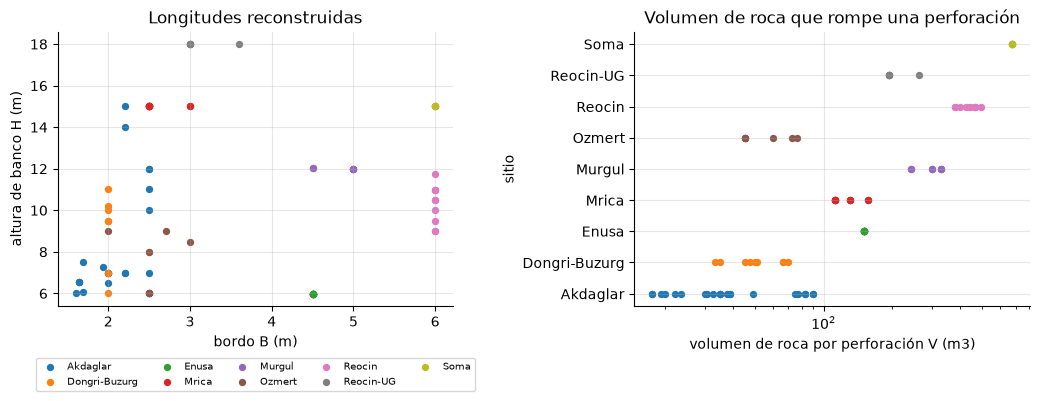

tiros con escala: 91 | V: 17.6 to 675 m3
volumen mayor sobre el menor: 38


In [5]:
# Reconstruir cada tiro con escala conocida y dibujar bordo contra altura de banco y el volumen de roca por perforación
patterns = {b.blast_id: bf.reconstruct_pattern(b) for b in train if bf.has_absolute_geometry(b)}
scaled_sites = [s for s in sites if any(b.site == s and b.blast_id in patterns for b in train)]
colors = plt.cm.tab10(np.arange(len(scaled_sites)))
fig, (left, right) = plt.subplots(1, 2, figsize=(10.5, 4.2))
for position, (color, site) in enumerate(zip(colors, scaled_sites)):
    members = [patterns[b.blast_id] for b in train if b.site == site and b.blast_id in patterns]
    left.scatter([p.burden_m for p in members], [p.bench_height_m for p in members], s=18, color=color, label=site)
    right.scatter([p.rock_volume_m3 for p in members], [position] * len(members), s=18, color=color)
left.set_xlabel("bordo B (m)")
left.set_ylabel("altura de banco H (m)")
left.set_title("Longitudes reconstruidas")
left.legend(fontsize=7, ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.17))
right.set_xscale("log")
right.xaxis.set_minor_formatter(plt.NullFormatter())
right.set_yticks(range(len(scaled_sites)), scaled_sites)
right.set_xlabel("volumen de roca por perforación V (m3)")
right.set_ylabel("sitio")
right.set_title("Volumen de roca que rompe una perforación")
fig.tight_layout()
plt.show()
volumes = [p.rock_volume_m3 for p in patterns.values()]
print(f"tiros con escala: {len(patterns)} | V: {min(volumes):.1f} to {max(volumes):.0f} m3")
print(f"volumen mayor sobre el menor: {max(volumes) / min(volumes):.0f}")

Los 91 tiros reconstruidos rompen entre 17.6 y 675 m3 de roca por perforación, una razón de 38. El panel izquierdo muestra que los sitios disparan en familias: todos los tiros de Enusa comparten un bordo y una altura de banco, y lo mismo los de Soma, Reocin usa un bordo con alturas de banco de 9 a 11.76 m, y Akdaglar varía ambos. El panel derecho muestra que la escala difiere entre sitios mucho más que dentro de ellos, lo que las razones adimensionales ocultaban. La figura muestra que las longitudes son dimensiones de banco plausibles si cada diámetro registrado es correcto; no muestra que lo sean.

### Paso 4: contrastar la reconstrucción con el artículo

Si un diámetro fuera erróneo, todas las longitudes de su sitio errarían por el mismo factor. El texto del artículo declara algunas longitudes directamente (por ejemplo "la altura de banco era de 6 m"). `verify_reconstruction` reconstruye cada tiro de un sitio y exige que cada rango declarado contenga al rango reconstruido, permitiendo solo la holgura que produce la impresión de las razones con dos decimales; lanza un `AssertionError` ante cualquier violación, así que también funciona como compuerta. La primera celda lista cada declaración que probó, y la segunda dibuja cada una como el rango que declara el artículo frente al rango que reconstruye el registro.

In [6]:
# Ejecutar la verificación del motor sobre el corpus y listar cada declaración dimensional del artículo que probó
report = bf.verify_reconstruction(train)
rows = []
for site, entry in report.items():
    for check in entry.get("checks", []):
        stated = f"{check['stated'][0]:g} to {check['stated'][1]:g}"
        got = f"{check['reconstructed'][0]:g} to {check['reconstructed'][1]:g}"
        rows.append((site, check["quantity"], stated, got, "sí" if check["ok"] else "no"))
header = ["sitio", "magnitud", "el artículo declara (m)",
          "reconstruido (m)", "cumple"]
show_table(header, rows, left=2)
print("declaraciones probadas:", len(rows), "| cumplidas:", sum(r[4] != "no" for r in rows))

| sitio | magnitud | el artículo declara (m) | reconstruido (m) | cumple |
|:---|:---|---:|---:|---:|
| Akdaglar | burden_m | 1.5 to 2.6 | 1.6 to 2.5 | sí |
| Dongri-Buzurg | bench_height_m | 6 to 11 | 6 to 11 | sí |
| Dongri-Buzurg | burden_m | 2 to 2.5 | 2 to 2.5 | sí |
| Dongri-Buzurg | spacing_m | 1.8 to 3.5 | 2.5 to 3.5 | sí |
| Enusa | bench_height_m | 6 to 6 | 5.984 to 5.984 | sí |
| Mrica | bench_height_m | 10 to 15 | 14.998 to 14.999 | sí |
| Murgul | bench_height_m | 12 to 12.05 | 11.999 to 12.014 | sí |
| Murgul | burden_m | 4.5 to 5 | 4.5 to 5 | sí |
| Murgul | spacing_m | 4.5 to 5.5 | 4.5 to 5.499 | sí |
| Ozmert | burden_m | 2 to 3 | 2 to 3 | sí |
| Ozmert | spacing_m | 2.5 to 3 | 2.5 to 3 | sí |
| Reocin | bench_height_m | 9 to 11.8 | 9 to 11.76 | sí |
| Reocin-UG | bench_height_m | 18 to 18 | 17.997 to 17.998 | sí |
| Soma | bench_height_m | 15 to 15 | 14.999 to 14.999 | sí |
| Soma | spacing_m | 7.5 to 7.5 | 7.5 to 7.5 | sí |

declaraciones probadas: 15 | cumplidas: 15


Las 15 declaraciones se cumplen, en nueve sitios. No son igualmente exigentes. Algunas son valores únicos, como el banco de 6 m de Enusa, que se reconstruye a 5.984 m; otras son anchas, como el banco de 10 a 15 m de Mrica, al que un diámetro erróneo aún podría ajustarse. La reconstrucción de Mrica, 14.998 m, queda en el extremo superior de su rango, lo que ya es informativo. La tabla da los veredictos; la figura siguiente muestra cuánto margen deja cada declaración.

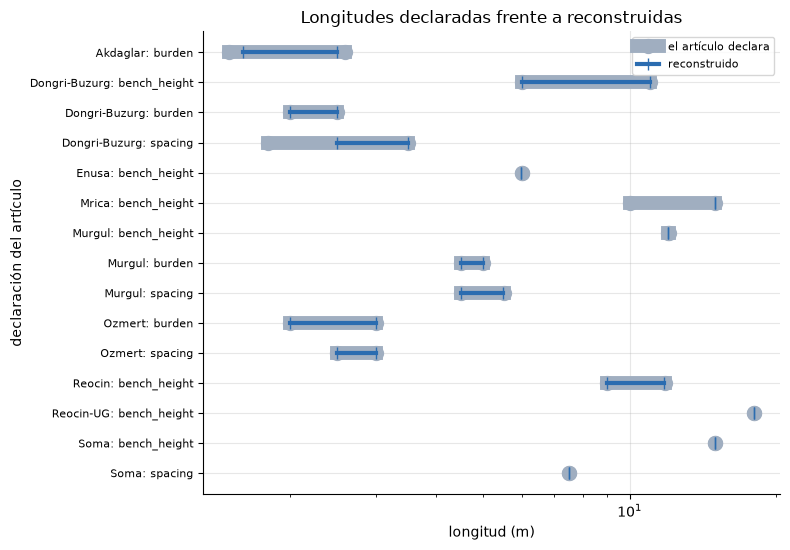

In [7]:
# Cada declaración como barra gris (lo que declara el artículo) y barra azul (lo que reconstruye el registro), en metros
checks = [(site, check) for site, entry in report.items() for check in entry.get("checks", [])]
labels = [f"{site}: {check['quantity'].removesuffix('_m')}" for site, check in checks]
stated_style = dict(color="#a0aec0", lw=10, marker="o", ms=10)
built_style = dict(color="#2b6cb0", lw=3, marker="|", ms=9)
fig, ax = plt.subplots(figsize=(8, 5.6))
for row, (site, check) in enumerate(checks):
    ax.plot(check["stated"], [row, row], **stated_style)
    ax.plot(check["reconstructed"], [row, row], **built_style)
ax.plot([], [], label="el artículo declara", **stated_style)
ax.plot([], [], label="reconstruido", **built_style)
ax.set_xscale("log")
ax.xaxis.set_minor_formatter(plt.NullFormatter())
ax.set_yticks(range(len(checks)), labels, fontsize=8)
ax.invert_yaxis()
ax.set_xlabel("longitud (m)")
ax.set_ylabel("declaración del artículo")
ax.set_title("Longitudes declaradas frente a reconstruidas")
ax.legend(loc="upper right", fontsize=8)
fig.tight_layout()
plt.show()

Cada fila es una declaración: la barra gris es el rango que declara el artículo y la barra azul lo que reconstruye el registro, en un eje logarítmico en metros. Cada barra azul queda dentro de su barra gris. Donde la barra gris es un solo punto (los bancos de Enusa, Reocin-UG y Soma, y el espaciamiento de Soma) el artículo declara un valor y la reconstrucción cae sobre él, que es el caso más exigente. Donde la barra gris es ancha, como en Mrica y Akdaglar, la verificación es débil. La figura no puede decir cuántos otros diámetros también pasarían; el paso siguiente los cuenta.

### Paso 5: ¿tiene poder la verificación?

Una verificación que no puede fallar no prueba nada. La narrativa de Soma es la prueba útil: declara dos longitudes, un banco de 15 m y un espaciamiento de 7.5 m, y el registro anota un conflicto sin resolver sobre su bordo, porque el artículo también cita un bordo y un diámetro que la tabla de razones no puede sostener a la vez. La celda reemplaza el diámetro de Soma por candidatos de 150 a 280 mm, con una grilla fina alrededor del valor registrado, reconstruye las longitudes para cada uno y cuenta cuántas de las dos longitudes declaradas acepta la verificación del motor, llamando a `verify_reconstruction` una vez por declaración. `patch.dict` coloca un candidato en el registro solo dentro de su bloque `with`, así que nada se filtra a las celdas siguientes.

In [8]:
# Probar otros diámetros de Soma: reconstruir sus longitudes y contar cuáles de las dos declaradas cumple cada uno
soma = [b for b in train if b.site == "Soma"]
registered = bf.SITE_GEOMETRY["Soma"]
sweep = []
grid = np.unique(np.concatenate([np.arange(150.0, 280.1, 2.0), np.arange(208.0, 212.01, 0.1)]).round(1))
for diameter in grid:
    candidate = dataclasses.replace(registered, hole_diameter_mm=float(diameter))
    with patch.dict(bf.SITE_GEOMETRY, {"Soma": candidate}):
        patterns_soma = [bf.reconstruct_pattern(b) for b in soma]
    met = 0
    for statement in registered.narrative:
        single = dataclasses.replace(candidate, narrative=(statement,))
        with patch.dict(bf.SITE_GEOMETRY, {"Soma": single}):
            try:
                bf.verify_reconstruction(soma)
                met += 1
            except AssertionError:
                pass
    sweep.append((diameter, patterns_soma[0].bench_height_m, patterns_soma[0].spacing_m, met))
passing = [d for d, _, _, met in sweep if met == len(registered.narrative)]
print("declaraciones por cumplir:", registered.narrative)
print(f"diámetros que cumplen ambas (mm): {min(passing):g} to {max(passing):g}")
print(f"ancho de esa ventana (mm): {max(passing) - min(passing):.1f}")
print(f"diámetro registrado (mm): {registered.hole_diameter_mm:g}")
print("nota del registro sobre Soma:", registered.note)

declaraciones por cumplir: (('bench_height_m', 15.0, 15.0), ('spacing_m', 7.5, 7.5))
diámetros que cumplen ambas (mm): 209.6 to 210.4
ancho de esa ventana (mm): 0.8
diámetro registrado (mm): 210
nota del registro sobre Soma: UNRESOLVED SOURCE CONFLICT. The same paragraph states a 5 m burden and a 21 cm diameter, and the ratio table cannot hold both: B/D is 28.57, and 5 / 0.21 is 23.8. Taking the diameter as authoritative gives a 6.00 m burden, which then reproduces the stated 7.5 m spacing and 15 m bench exactly, so two of three constraints select it. A reading with D = 175 mm and B = 5 m satisfies the ratio but fails the bench height. The burden constraint is therefore NOT asserted here and the conflict travels with every Soma case.


La verificación acepta diámetros de 209.6 a 210.4 mm, una ventana de 0.8 mm alrededor de los 210 mm registrados, y rechaza todo otro candidato del barrido. La nota del registro, impresa arriba, anota el conflicto: la otra lectura del artículo, 175 mm con un bordo de 5 m, satisface la razón pero falla la altura de banco. Dos de tres restricciones seleccionan 210 mm y la tercera no se afirma. Así que la verificación sí discrimina, y lo hace con nitidez cuando las declaraciones son valores únicos.

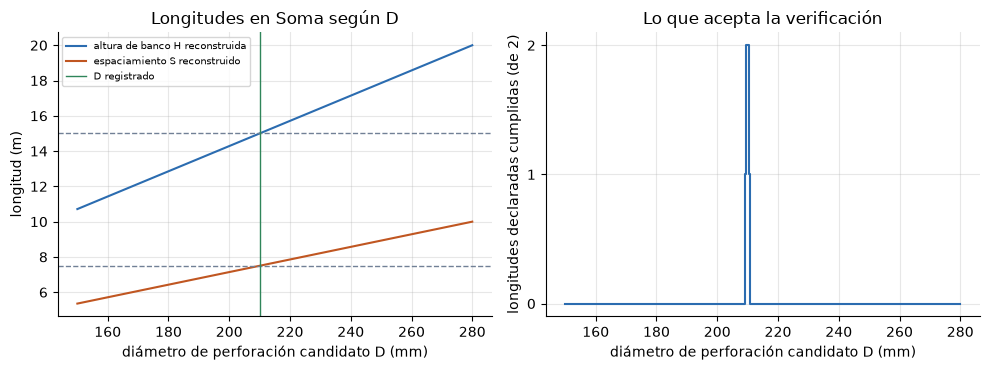

In [9]:
# Altura de banco y espaciamiento reconstruidos frente al diámetro candidato, y las declaraciones cumplidas en cada uno
diameters, heights, spacings, met = (np.array(column) for column in zip(*sweep))
fig, (left, right) = plt.subplots(1, 2, figsize=(10, 3.8))
left.plot(diameters, heights, color="#2b6cb0", label="altura de banco H reconstruida")
left.plot(diameters, spacings, color="#c05621", label="espaciamiento S reconstruido")
for _, stated_low, _ in registered.narrative:
    left.axhline(stated_low, color="#718096", lw=1, ls="--")
left.axvline(registered.hole_diameter_mm, color="#2f855a", lw=1, label="D registrado")
left.set_xlabel("diámetro de perforación candidato D (mm)")
left.set_ylabel("longitud (m)")
left.set_title("Longitudes en Soma según D")
left.legend(fontsize=7)
right.step(diameters, met, where="mid", color="#2b6cb0")
right.set_yticks(range(len(registered.narrative) + 1))
right.set_xlabel("diámetro de perforación candidato D (mm)")
right.set_ylabel("longitudes declaradas cumplidas (de 2)")
right.set_title("Lo que acepta la verificación")
fig.tight_layout()
plt.show()

El panel izquierdo muestra por qué: la altura de banco y el espaciamiento reconstruidos crecen en proporción al diámetro, y cada uno cruza su línea punteada, el valor declarado, exactamente en el diámetro registrado. El panel derecho muestra el veredicto: 2 de 2 longitudes declaradas cumplidas en el valor registrado y ninguna en otro lugar. La lectura de 175 mm de la nota del registro falla la altura de banco. La figura no muestra que la verificación pueda elegir entre dos lecturas que ambas calzan con el texto; en Soma no puede probar el bordo, y en sitios cuyas declaraciones son rangos anchos aceptaría muchos más diámetros.

### Paso 6: donde nada fija la escala

Miami no publica diámetro de perforación ni longitud absoluta alguna, así que no existe una reconstrucción honesta. El motor lanza `GeometryUnavailable` en vez de adivinar, y `has_absolute_geometry` es el predicado que usa todo predictor que necesita un volumen para decidir si responde. La primera celda cuenta los tiros con escala resoluble y captura la negativa. La segunda pregunta cuánto costaría una suposición: registra para Miami, uno por vez, diámetros entre el menor (76 mm) y el mayor (229 mm) usados en los otros sitios, y reconstruye el volumen de roca de sus seis tiros.

In [10]:
# Pedir al motor la escala de Miami: la negativa que lanza y el conteo de tiros que sí tienen escala
miami = [b for b in train if b.site == "Miami"]
try:
    bf.reconstruct_pattern(miami[0])
except bf.GeometryUnavailable as refusal:
    print("negativa del motor:", str(refusal)[:105], "...")
resolvable = sum(bf.has_absolute_geometry(b) for b in train)
print(f"tiros con escala resoluble: {resolvable} de {len(train)}")
print("tiros de Miami con escala resoluble:", sum(bf.has_absolute_geometry(b) for b in miami))

negativa del motor: Mi1: Miami Mine, Arizona, USA publishes no hole diameter and no absolute dimension, so its scale cannot b ...
tiros con escala resoluble: 91 de 97
tiros de Miami con escala resoluble: 0


El motor se niega con palabras, nombrando el sitio y la información que falta, y el conteo es 91 de 97: ninguno de los seis tiros de Miami tiene escala. Todo predictor que necesite un volumen debe abstenerse en ellos, y notebooks posteriores muestran esas abstenciones en el benchmark. La negativa es un resultado, no una falla: el corpus contiene un sitio donde la ecuación clásica no puede aplicarse, y el motor lo dice.

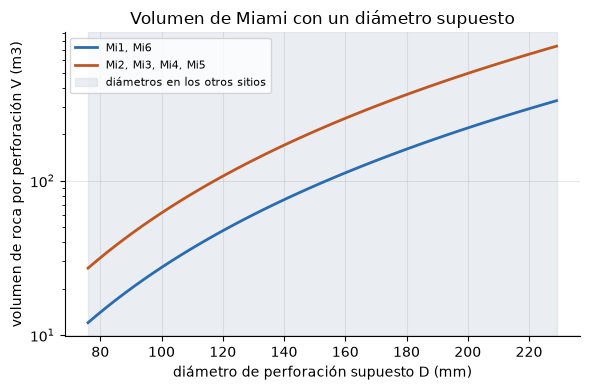

razón de volumen entre D = 229 y D = 76 mm: 27.4


In [11]:
# Qué haría un diámetro supuesto en Miami: volumen de roca de sus seis tiros con los diámetros de los otros sitios
diameters = np.arange(76.0, 230.0, 3.0)
volumes = []
for diameter in diameters:
    guess = dataclasses.replace(bf.SITE_GEOMETRY["Miami"], hole_diameter_mm=float(diameter))
    with patch.dict(bf.SITE_GEOMETRY, {"Miami": guess}):
        volumes.append([bf.reconstruct_pattern(b).rock_volume_m3 for b in miami])
volumes = np.array(volumes)
fig, ax = plt.subplots(figsize=(6, 4))
groups = {}
for column, blast in enumerate(miami):
    groups.setdefault(round(volumes[0, column], 1), []).append((column, blast.blast_id))
for color, members in zip(["#2b6cb0", "#c05621"], groups.values()):
    ax.plot(diameters, volumes[:, members[0][0]], lw=2, color=color, label=", ".join(name for _, name in members))
ax.axvspan(76, 229, color="#cbd5e0", alpha=0.4, label="diámetros en los otros sitios")
ax.set_yscale("log")
ax.set_xlabel("diámetro de perforación supuesto D (mm)")
ax.set_ylabel("volumen de roca por perforación V (m3)")
ax.set_title("Volumen de Miami con un diámetro supuesto")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()
print(f"razón de volumen entre D = 229 y D = 76 mm: {volumes[-1, 1] / volumes[0, 1]:.1f}")

Un diámetro supuesto no es un error pequeño. El volumen de roca por perforación de los mismos tiros de Miami sigue una ley de potencia en el diámetro supuesto y difiere en un factor de 27.4 entre 76 mm y 229 mm, los dos extremos en uso en otros sitios; la masa de explosivo se mueve con él, y lo mismo haría toda predicción clásica construida sobre ellos. Hay dos curvas porque los seis tiros de Miami vienen en dos geometrías. La figura no dice qué diámetro es el correcto. Ese es el punto: nada en la fuente lo dice, así que el motor se niega.

## Resultados

**Respuesta:** Sí, con una longitud guardada por sitio. Un diámetro de perforación registrado convierte cada razón en metros con cuatro multiplicaciones, y da a los 91 tiros de nueve sitios un volumen de roca de 17.6 a 675 m3 por perforación. La conversión se puede probar: se cumplen las 15 longitudes que declara el texto del artículo, y la prueba no es una formalidad, porque en Soma la verificación del motor acepta solo diámetros de 209.6 a 210.4 mm. Donde nada fija la escala (los seis tiros de Miami) el motor se niega, y una suposición movería el volumen de roca en un factor de 27.4.

**Qué se sigue.** Toda predicción clásica del tema 02 hereda este registro: sus volúmenes y masas valen lo que valen los diámetros, y cada predicción puede nombrar de dónde salió su diámetro (citado, derivado o ausente). Los sitios cuyas declaraciones son valores únicos son los mejor verificados; aquellos cuyas declaraciones son rangos anchos se verifican solo de forma laxa.

**Lo que este notebook no muestra.** Coincidir con el texto del artículo prueba que las longitudes son coherentes con lo que escribieron los autores, no que lo midieran correctamente. El diámetro de Reocin-UG se derivó de la altura de banco que la verificación luego prueba, así que esa declaración se cumple por construcción. La verificación no puede elegir entre dos lecturas que ambas satisfacen el texto, y nada aquí dice qué tan exacta será una predicción hecha con estas longitudes.

## Resumen

- Un diámetro registrado por sitio convierte cada razón en metros: cuatro multiplicaciones, un volumen de roca y una masa de explosivo.
- `verify_reconstruction` prueba el resultado contra las 15 longitudes que declara el texto del artículo, y las 15 se cumplen.
- La verificación tiene poder: en Soma acepta una ventana de 0.8 mm alrededor del diámetro registrado y nada más en un barrido de 150 a 280 mm.
- Donde no se publica ninguna longitud (Miami) el motor se niega, una suposición cambiaría el volumen en un factor de 27.4, y 91 de los 97 tiros siguen siendo utilizables por los predictores clásicos.
- Siguiente: el notebook 03 abre la compuerta de integridad sobre el propio corpus y el control negativo que alimenta la negativa (nivel 4).

## Referencias

- Hudaverdi, Kulatilake y Kuzu 2010, https://doi.org/10.1002/nag.957 (el corpus, las narrativas de sitio y las razones impresas)
- `blastfrag` 0.4.0, el motor, en PyPI: https://pypi.org/project/blastfrag/